# CPE 613 Term Project — Phase I: every experiment in one notebook

**Debt Collection Strategy Allocation using Mathematical Programming and Meta-Heuristics**
Yuil Tripathee (69070701612) · Sawit Koseeyaumporn (69070701621)

This notebook groups the Phase I report (`docs/PHASE1_REPORT.pdf`) and the code behind it into one place. Every experiment is **re-run live** with the project's own code (`src/optimizer.py`, `src/03b_phase1_benchmark.py`) and compared with the numbers saved for the report (`data/phase1_benchmark.json`).

| Part | Experiment | Report section |
| :-- | :-- | :-- |
| A | Problem, dataset, model and problem size | §3–7 |
| B · E1 | Exact MILP (HiGHS) | §8.1, §9 |
| B · E2–E3 | LP relaxation, shadow prices, MILP +1-unit sensitivity | §8.1, §9.3 |
| B · E4 | Dynamic-programming relaxation (upper bound) | §8.1, §9.2 |
| B · E5 | Greedy baseline | §8.1, §10.1 |
| B · E6 | Custom Branch & Bound | §8.1, §9.2 |
| B · E7 | Genetic Algorithm vs Simulated Annealing (3 seeds) | §8.2, §9 |
| B · E8 | SA initial-temperature ablation | §9.2 |
| C · E9 | Scaling benchmark: 6 cohorts (N = 30, 100, 300; proportional vs frozen capacity) | §9.1 |
| C · E10 | Strategy mix and shadow prices across cohorts | §9.3, §10.1 |
| C · E11 | Wilcoxon signed-rank test, SA vs GA | §9.2 |
| D · E12 | Multi-objective preview: ε-constraint Pareto front (Phase II) | — |
| E | Verification checks and conclusions | §10 |

**How to run:** select the project's `.venv` kernel and *Run All* (≈ 3 minutes on a laptop). Nothing is written to `data/` — the notebook only reads the saved results to compare against.

In [1]:
# ---- setup ------------------------------------------------------------------
import importlib.util, json, sys, time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import wilcoxon

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import optimizer as opt
from optimizer import (STRATEGIES, DEFAULT_CFG, K, Instance, solve_milp, lp_relaxation, dp_budget, greedy,
                       branch_and_bound, genetic_algorithm, simulated_annealing, pareto_front, problem_size)

# the Phase I benchmark script (file name starts with a digit, so import it by path)
spec = importlib.util.spec_from_file_location("bench", ROOT / "src" / "03b_phase1_benchmark.py")
bench = importlib.util.module_from_spec(spec); spec.loader.exec_module(bench)
# the benchmark script switches matplotlib to "Agg"; switch back to inline plots for the notebook
%matplotlib inline

pd.set_option("display.max_columns", 30, "display.width", 200, "display.float_format", lambda v: f"{v:,.4g}" if abs(v) < 1e4 else f"{v:,.0f}")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "font.size": 10})
COLORS = ["#a9a9a9", "#8cc0de", "#2a6f97", "#e8a964", "#c46a24", "#6e2a0e"]   # none … legal
KEYS = [s["key"] for s in STRATEGIES]
SEEDS = bench.SEEDS                                                                     # [0, 1, 2]

REPORT = json.loads((ROOT / "data" / "phase1_benchmark.json").read_text())   # numbers used in the report
MODEL = json.loads((ROOT / "data" / "model_report.json").read_text())
pool = pd.read_csv(ROOT / "data" / "accounts_pool.csv")
thb = lambda v: f"฿{v:,.2f}"
print(f"accounts pool: {len(pool)} rows · saved benchmark cohorts: {list(REPORT['results'])}")

accounts pool: 300 rows · saved benchmark cohorts: ['N30_main', 'N30_unseenB', 'N100_prop', 'N300_prop', 'N100_frozen', 'N300_frozen']


---
## Part A — Problem, dataset and model

### A1. The decision problem (report §3)
Every collection cycle, each delinquent account $i$ gets **exactly one** of six channels $k$. Stronger channels recover more (lift $\lambda_k$ multiplies the account's base recovery rate $\rho_i$) but cost more and use scarce resources. The single-objective goal is to **maximise expected net recovery in THB**.

In [2]:
strat = pd.DataFrame(STRATEGIES).rename(columns={"lift": "lift λ", "cost": "fixed cost ฿", "cost_pct": "% of balance", "commission": "commission φ", "hours": "call hours"})
display(strat)
display(pd.Series({k: v for k, v in DEFAULT_CFG.items() if k not in ("strategy_priority",)}, name="N=30 limits (DEFAULT_CFG)").to_frame())

,key,name,lift λ,fixed cost ฿,% of balance,commission φ,call hours
0,none,No action / self-cure,0.3,0,0,0,0
1,sms,SMS + LINE OA reminder,0.55,25,0,0,0
2,call,In-house call center,1,350,0,0,0.75
3,field,Field collector visit,1.4,1800,0,0,0
4,agency,External collection agency,1.7,500,0,0.25,0
5,legal,Legal action (law firm),2.3,8000,0.02,0,0


,N=30 limits (DEFAULT_CFG)
budget,150000
call_hours,12
field_slots,5
hard_cap,10
legal_retainer,40000
legal_min_cases,3
legal_min_balance,100000
must_act_dpd,90
unreachable_factor,0.4
rate_cap,0.9


### A2. Dataset (report §6)
`src/01_explore.py` and `src/02_model_and_dataset.py` turn the Kaggle **LendingClub** file (2,260,668 loans × 145 columns, issued 2007–2018) into the portfolio used here:

1. keep defaulted loans (*Charged Off*, *Default*, *Does not meet the credit policy. Status: Charged Off*) → **262,447**; exposure $EAD = \text{funded} - \text{principal repaid} > \$500$ → **260,640**;
2. two-part hurdle model on 24 pre-collection features (75/25 split, seed 613): classifier $P(\text{pay}>0)$ and regressor $E[\text{rate}\mid\text{pay}]$;
3. stratified sample of **300 accounts** by grade, USD → THB at 33, synthetic `dpd` and `reachable` (seed 613), and
$\rho_i = P(\text{pay})\cdot E[\text{rate}\mid\text{pay}]\cdot e^{-0.004(\text{dpd}_i-30)}$, clipped to $[0.01, 0.60]$.

Those two scripts need the 1 GB raw `loan.csv`, so this notebook starts from their saved outputs.

In [3]:
m = MODEL
display(pd.Series({
    "defaulted loans used": m["n_defaulted_used"], "classifier AUC": m["classifier_auc"], "AUC with grade only": m["classifier_auc_grade_only"],
    "Brier score": m["classifier_brier"], "rate MAE | recovered": m["rate_mae_given_recovered"],
    "mean actual rate": m["mean_actual_rate"], "mean predicted rate": m["mean_predicted_rate"]}, name="recovery model (test set)").to_frame())
grade = pd.DataFrame(m["grade_profile"]).set_index("grade")
grade["in 300 pool"] = pd.Series(m["pool_grade_counts"])
display(grade)
display(pool.head(8))

,recovery model (test set)
defaulted loans used,"260,640"
classifier AUC,0.766
AUC with grade only,0.5299
Brier score,0.1722
rate MAE | recovered,0.0767
mean actual rate,0.1061
mean predicted rate,0.1061


,n,mean_ead_thb,p_recovered,mean_rate,in 300 pool
grade,,,,,
A,13621,268142,0.5937,0.1035,25
B,50640,287813,0.6615,0.1048,50
C,82763,342003,0.6763,0.1052,75
D,59324,391807,0.6832,0.106,65
E,35419,468807,0.7009,0.1092,45
F,14323,531779,0.7244,0.1123,25
G,4550,576353,0.7215,0.1111,15


,account_id,grade,sub_grade,int_rate,term_m,dpd,reachable,balance_thb,annual_inc_thb,dti,p_pay,rate_if_pay,rho,hist_recoveries_usd,ead_usd
0,TH0001,B,B5,11.47,36,60,1,"154,000","2,145,000",23.74,0.836,0.178,0.132,627.1,"4,666"
1,TH0002,A,A5,7.97,36,120,1,"101,900","594,000",33.2,0.2804,0.1583,0.031,0,"3,087"
2,TH0003,D,D2,17.27,36,90,1,"123,900","1,300,000",39.75,0.4616,0.1782,0.0647,532.1,"3,754"
3,TH0004,D,D2,17.99,60,180,1,"435,200","2,805,000",21.4,0.7612,0.1537,0.0642,"1,704","13,187"
4,TH0005,C,C3,13.99,36,60,1,"94,000","1,815,000",27.08,0.644,0.1663,0.095,400.2,"2,847"
5,TH0006,C,C3,15.8,60,120,1,"356,800","1,617,000",19.98,0.9297,0.1366,0.0886,6.49,"10,811"
6,TH0007,D,D1,17.47,36,180,1,"154,300","2,376,000",3.81,0.1493,0.138,0.0113,0,"4,675"
7,TH0008,D,D1,16.29,36,60,0,"199,800","2,475,000",5.08,0.9926,0.0961,0.0846,352.7,"6,055"


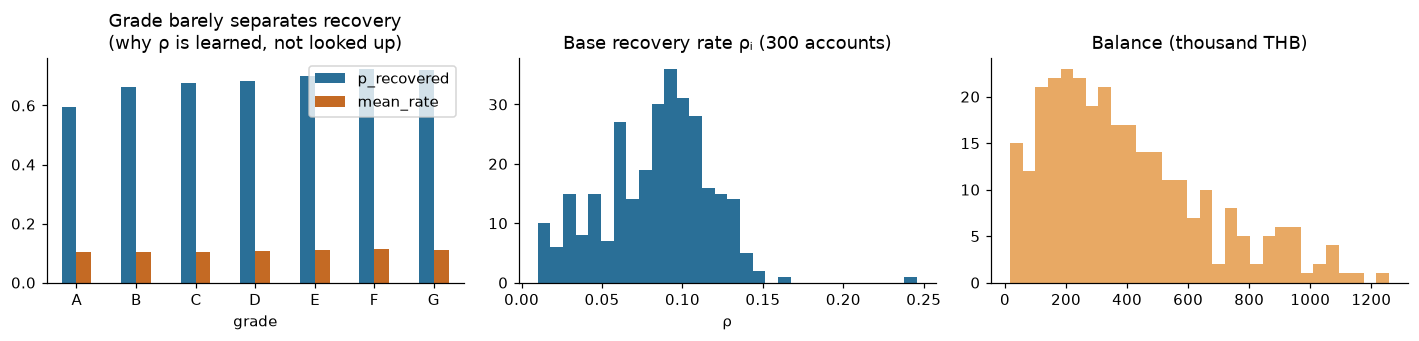

synthetic DPD shares: {30: 0.23, 60: 0.28, 90: 0.18, 120: 0.19, 180: 0.12} | reachable share: 0.79


In [4]:
fig, ax = plt.subplots(1, 3, figsize=(13, 3.2))
grade[["p_recovered", "mean_rate"]].plot.bar(ax=ax[0], color=[COLORS[2], COLORS[4]], rot=0)
ax[0].set_title("Grade barely separates recovery\n(why ρ is learned, not looked up)")
ax[1].hist(pool["rho"], bins=30, color=COLORS[2]); ax[1].set_title("Base recovery rate ρᵢ (300 accounts)"); ax[1].set_xlabel("ρ")
ax[2].hist(pool["balance_thb"] / 1e3, bins=30, color=COLORS[3]); ax[2].set_title("Balance (thousand THB)")
plt.tight_layout(); plt.show()
print("synthetic DPD shares:", pool["dpd"].value_counts(normalize=True).sort_index().round(2).to_dict(),
      "| reachable share:", round(pool["reachable"].mean(), 3))

### A3. Model formulation (report §5)
Decision variables: $x_{i,k}\in\{0,1\}$ for eligible pairs $(i,k)\in A$, and $y\in\{0,1\}$ (law firm engaged). With $v_{i,k} = B_i\, r_{i,k}(1-\varphi_k) - c_{i,k}$ and $r_{i,k} = \min(0.9,\ \rho_i\lambda_k u_{i,k})$:

$$\max Z = \sum_{(i,k)\in A} v_{i,k}x_{i,k} - F y$$

| | Constraint | N = 30 value |
|:--|:--|:--|
| C1 | $\sum_k x_{i,k}=1\ \forall i$ — one strategy per account | — |
| C2 | $\sum c_{i,k}x_{i,k} + Fy \le B_{\max}$ — budget | ฿150,000 |
| C3 | $\sum_i 0.75\,x_{i,2}\le H$ — call-center hours | 12 h |
| C4 | $\sum_i x_{i,3}\le V$ — field visits | 5 |
| C5 | $\sum_i (x_{i,4}+x_{i,5})\le M$ — agency + legal cap | 10 |
| C6 | $x_{i,5}\le y$ — legal only if the firm is engaged (disaggregated) | — |
| C7 | $L\,y\le\sum_i x_{i,5}$ — minimum legal batch | $F$ = ฿40,000, $L$ = 3 |
| C8 | binary variables | — |

Eligibility removes pairs before solving: legal needs $B_i\ge$ ฿100,000; accounts with $\text{dpd}\ge 90$ cannot get *none*.

In [5]:
df30 = pool.iloc[:30].reset_index(drop=True)
cfg30 = bench.make_cfg(30, scale_caps=False)
inst30 = Instance(df30, cfg30)

V = pd.DataFrame(np.where(inst30.allowed, inst30.V, np.nan), columns=KEYS, index=df30["account_id"])
print("Net value v_ik (THB) for the first 6 accounts — NaN = not eligible:")
display(V.head(6).round(0))

dims, size = bench.count_model_dimensions(inst30), problem_size(inst30)
print("model dimensions:", dims)
print(f"search space Π|K_i| = {size['size']:.3e}  (log10 = {size['log10']:.2f}); unrestricted 6^30 = {size['unrestricted']:.3e}")
print(f"course minimum 3e6 exceeded by a factor of {size['size'] / 3e6:.2e}")

Net value v_ik (THB) for the first 6 accounts — NaN = not eligible:


,none,sms,call,field,agency,legal
account_id,,,,,,
TH0001,"6,098","11,155","19,978","26,659","25,418","35,674"
TH0002,NaN,"1,712","2,809","2,622","3,528","-2,773"
TH0003,NaN,"4,384","7,666","9,423","9,721","7,960"
TH0004,NaN,"15,342","27,590","37,316","35,123","47,558"
TH0005,"2,679","4,886","8,580","10,702","10,886",NaN
TH0006,NaN,"17,362","31,262","42,457","39,806","57,573"


model dimensions: {'accounts': 30, 'binary_x': 160, 'binary_y': 1, 'total_vars': 161, 'c1_assign': 30, 'c2_c5_resources': 4, 'c6_legal_link': 26, 'c7_legal_min': 1, 'total_constraints': 61}
search space Π|K_i| = 5.536e+21  (log10 = 21.74); unrestricted 6^30 = 2.211e+23
course minimum 3e6 exceeded by a factor of 1.85e+15


---
## Part B — Experiments on the main instance `N30_main` (TH0001–TH0030)

### E1. Exact MILP with HiGHS
`solve_milp` builds the constraint matrix with `build_lp` and calls `scipy.optimize.milp` (HiGHS branch-and-cut). This gives the proven optimum $Z^*$ that every other method is measured against.

In [6]:
ex = solve_milp(inst30)
Z = ex["objective"]
saved = REPORT["results"]["N30_main"]["exact_milp"]
print(f"Z* = {thb(Z)}   time = {ex['time']:.3f}s   status: {ex['status']}")
print(f"saved in report: {thb(saved['objective'])}   match: {abs(Z - saved['objective']) < 0.01}")
print(f"cost {thb(ex['cost'])} / {thb(cfg30['budget'])} · call hours {ex['call_hours']} / {cfg30['call_hours']} · field {ex['field']} / {cfg30['field_slots']} · hard {ex['hard']} / {cfg30['hard_cap']} · legal {ex['legal']} (law firm y = {ex['law_firm']})")
print("violation of the optimal plan:", inst30.violation(ex["assign"]))

idx = np.arange(inst30.n)
plan = df30[["account_id", "grade", "dpd", "reachable", "balance_thb", "rho"]].assign(
    strategy=[KEYS[k] for k in ex["assign"]], exp_recovery=inst30.R[idx, ex["assign"]].round(), cost=inst30.C[idx, ex["assign"]].round(),
    net_value=inst30.V[idx, ex["assign"]].round())
display(plan)

Z* = ฿1,099,661.34   time = 0.050s   status: Optimization terminated successfully. (HiGHS Status 7: Optimal)
saved in report: ฿1,099,661.34   match: True
cost ฿147,575.00 / ฿150,000.00 · call hours 10.5 / 12.0 · field 5 / 5 · hard 10 / 10 · legal 5 (law firm y = 1)
violation of the optimal plan: 0.0


,account_id,grade,dpd,reachable,balance_thb,rho,strategy,exp_recovery,cost,net_value
0,TH0001,B,60,1,"154,000",0.132,call,"20,328",350,"19,978"
1,TH0002,A,120,1,"101,900",0.031,call,"3,159",350,"2,809"
2,TH0003,D,90,1,"123,900",0.0647,call,"8,016",350,"7,666"
3,TH0004,D,180,1,"435,200",0.0642,agency,"47,498",500,"35,123"
4,TH0005,C,60,1,"94,000",0.095,call,"8,930",350,"8,580"
5,TH0006,C,120,1,"356,800",0.0886,field,"44,257","1,800","42,457"
6,TH0007,D,180,1,"154,300",0.0113,call,"1,744",350,"1,394"
7,TH0008,D,60,0,"199,800",0.0846,agency,"28,735",500,"21,051"
8,TH0009,F,90,1,"891,600",0.0859,legal,"176,153","25,832","150,321"
9,TH0010,D,90,1,"493,500",0.0926,field,"63,977","1,800","62,177"


### E2–E3. LP relaxation, shadow prices and the +1-unit MILP check
Dropping integrality gives an **upper bound** $\bar Z_{LP}\ge Z^*$ and a **shadow price** (dual) for each resource: the value of one more unit. Because the real problem is integer, the report cross-checks each dual by re-solving the MILP with one extra unit (exactly what `run_instance` does).

In [7]:
lp = lp_relaxation(inst30)
print(f"LP bound = {thb(lp['bound'])}   root integrality gap = {100 * (lp['bound'] - Z) / Z:.3f}%   fractional variables = {lp['fractional']}")
rows = []
for key, step in [("budget", 1000.0), ("call_hours", 0.75), ("field_slots", 1), ("hard_cap", 1)]:
    gain = solve_milp(Instance(df30, dict(cfg30, **{key: cfg30[key] + step})))["objective"] - Z
    rows.append(dict(resource=key, step=step, lp_shadow_per_unit=lp["shadow"][key], lp_shadow_x_step=lp["shadow"][key] * step, milp_gain=gain))
sens = pd.DataFrame(rows).set_index("resource")
display(sens)

LP bound = ฿1,115,179.58   root integrality gap = 1.411%   fractional variables = 17


,step,lp_shadow_per_unit,lp_shadow_x_step,milp_gain
resource,,,,
budget,"1,000",1.277,"1,277","5,304"
call_hours,0.75,0,0,0
field_slots,1,"7,687","7,687","9,283"
hard_cap,1,"7,113","7,113","7,049"


**Reading it (report §10.1):** call-center hours have a **zero** shadow price (10.5 of 12 h used — overtime adds nothing), while one more field visit is worth ≈ ฿7.7k–9.3k (cost ≈ ฿1.8k) and one more agency/legal slot ≈ ฿7k. Budget returns ≈ ฿1.28–5.3 per extra baht, so more budget pays for itself.

### E4. Dynamic-programming relaxation
`dp_budget` keeps **only the budget** (stage = account, state = remaining budget in ฿100 steps) and solves it for $y=0$ and $y=1$. It ignores hours, visits and the cap, so its answer is an upper bound that breaks other limits.

In [8]:
dp = dp_budget(inst30)
print(f"DP value = {thb(dp['objective'])}  (+{100 * (dp['objective'] - Z) / Z:.2f}% above Z*)   time {dp['time']:.2f}s")
print(f"feasible for the full model? {dp['feasible_full']}  -> hard-collection accounts {dp['hard']} (cap {cfg30['hard_cap']}), call hours {dp['call_hours']} (cap {cfg30['call_hours']})")
print(f"bound hierarchy  DP {dp['objective']:,.0f} ≥ LP {lp['bound']:,.0f} ≥ Z* {Z:,.0f}:", dp["objective"] >= lp["bound"] >= Z)

DP value = ฿1,148,052.27  (+4.40% above Z*)   time 0.00s
feasible for the full model? False  -> hard-collection accounts 24 (cap 10), call hours 0.0 (cap 12.0)
bound hierarchy  DP 1,148,052 ≥ LP 1,115,180 ≥ Z* 1,099,661: True


### E5. Greedy baseline
Start every account at its cheapest allowed strategy and repeatedly apply the feasible single-account upgrade with the best Δvalue/Δcost.

In [9]:
gr = greedy(inst30)
print(f"Greedy = {thb(gr['objective'])}   gap = {100 * (Z - gr['objective']) / Z:.2f}%   time {gr['time']:.2f}s")
print(f"law firm used: y = {gr['law_firm']} · spent only {thb(gr['cost'])} of {thb(cfg30['budget'])}")
display(pd.DataFrame({"Greedy": gr["mix"], "MILP optimum": ex["mix"]}).T)

Greedy = ฿927,780.84   gap = 15.63%   time 0.05s
law firm used: y = 0 · spent only ฿18,925.00 of ฿150,000.00


,none,sms,call,field,agency,legal
Greedy,0,1,14,5,10,0
MILP optimum,0,1,14,5,5,5


**Why Greedy fails (report §10.1):** one legal case alone costs the ฿40,000 retainer and violates $L=3$, so a one-account-at-a-time rule **never** opens the law firm ($y=0$). It parks high balances at the agency (25% commission) and leaves most of the budget unused.

### E6. Custom Branch & Bound
Textbook best-bound B&B on the LP relaxation (`branch_and_bound`): the Greedy plan is the first incumbent, branch on $y$ first, then the most fractional $x_{i,k}$; prune when the LP bound cannot beat the incumbent.

In [10]:
df30b = pool.iloc[30:60].reset_index(drop=True)
inst30b = Instance(df30b, cfg30)
Zb = solve_milp(inst30b)["objective"]
rows = []
for label, inst_, z_ in [("N30_main", inst30, Z), ("N30_unseenB", inst30b, Zb)]:
    bb = branch_and_bound(inst_, max_nodes=10_000)
    rows.append(dict(cohort=label, bnb_objective=bb["objective"], milp_Z=z_, gap_pct=100 * (z_ - bb["objective"]) / z_, time_s=bb["time"], **bb["log"]))
display(pd.DataFrame(rows).set_index("cohort"))

,bnb_objective,milp_Z,gap_pct,time_s,nodes,pruned_bound,pruned_infeasible,integer_leaves,root_bound,incumbent_start,proved_optimal
cohort,,,,,,,,,,,
N30_main,"1,099,661","1,099,661",0,5.245,6267,3133,0,1,"1,115,180","927,781",True
N30_unseenB,"1,365,227","1,365,227",0,1.236,1535,767,0,1,"1,391,560","1,168,895",True


Both instances close with a **proof of optimality** (`proved_optimal = True`) and reach exactly $Z^*$. Node counts depend on which LP vertex the installed SciPy/HiGHS returns: `N30_main` closes at 6,267 nodes (as in `results_N30.json`; the Phase I report's run stopped at its 10,000-node budget with the heap still open). `N30_unseenB` closes here at about 1,500 nodes vs 1,697 in the report. The optimum is the same either way.

### E7. Meta-heuristics: Genetic Algorithm vs Simulated Annealing (seeds 0, 1, 2)
Both encode a plan as an integer vector $a_i\in K_i$ (C1 and eligibility always hold) and penalise the remaining violations:
$\text{fit}(a) = Z(a) - 10^5\cdot\text{violation}(a)$.

| | Setting |
|:--|:--|
| GA | population 120, 400 generations (48,000 evaluations), 2 elites, tournament 3, uniform crossover $p_c=0.9$, mutation $1.5/N$ |
| SA | $T_0=10^6$, geometric $\alpha=0.99975$, 60,000 steps; single-gene flip + 30% swap; Metropolis acceptance |

In [11]:
ga_runs = [genetic_algorithm(inst30, seed=s) for s in SEEDS]
sa_runs = [simulated_annealing(inst30, seed=s) for s in SEEDS]
saved = REPORT["results"]["N30_main"]
rows = []
for alg, runs, saved_runs in [("GA", ga_runs, saved["ga_runs"]), ("SA", sa_runs, saved["sa_runs"])]:
    for s, r, sr in zip(SEEDS, runs, saved_runs):
        rows.append(dict(alg=alg, seed=s, objective=r["objective"], gap_pct=100 * (Z - r["objective"]) / Z, feasible=bool(r["feasible"]),
                         legal=r["legal"], time_s=r["time"], report_objective=sr["objective"]))
runs7 = pd.DataFrame(rows)
runs7["same_as_report"] = (runs7["objective"] - runs7["report_objective"]).abs() < 0.01
display(runs7)
display(pd.DataFrame({"GA": bench.summarize_runs(ga_runs, Z), "SA": bench.summarize_runs(sa_runs, Z)}).loc[
    ["mean", "std", "gap_mean_pct", "gap_worst_pct", "feasible_count", "optimal_hit_count", "law_firm_active_count", "mean_time_s"]])

,alg,seed,objective,gap_pct,feasible,legal,time_s,report_objective,same_as_report
0,GA,0,"1,096,132",0.321,True,5,1.835,"1,096,132",True
1,GA,1,"1,099,661",0,True,5,1.835,"1,099,661",True
2,GA,2,"1,096,535",0.2843,True,5,1.826,"1,096,535",True
3,SA,0,"1,099,661",0,True,5,1.939,"1,099,661",True
4,SA,1,"1,099,661",0,True,5,1.949,"1,099,661",True
5,SA,2,"1,099,661",0,True,5,1.975,"1,099,661",True


,GA,SA
mean,"1,097,443","1,099,661"
std,"1,932",0
gap_mean_pct,0.2018,0
gap_worst_pct,0.321,0
feasible_count,3,3
optimal_hit_count,1,3
law_firm_active_count,3,3
mean_time_s,1.832,1.954


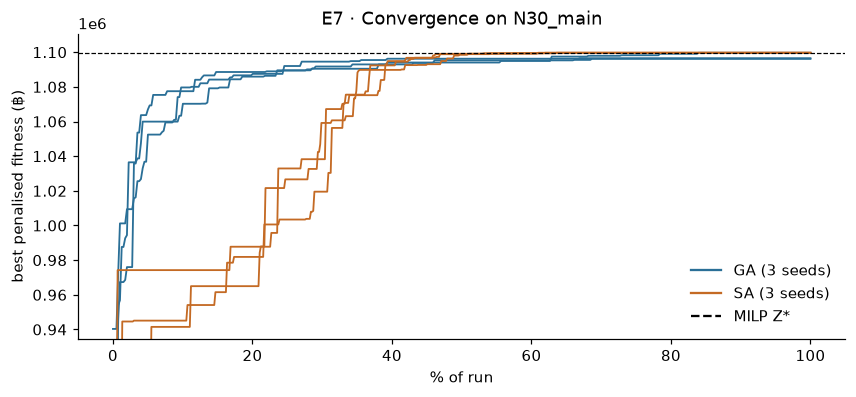

In [12]:
fig, ax = plt.subplots(figsize=(9, 3.6))
for r in ga_runs: ax.plot(np.linspace(0, 100, len(r["history"])), r["history"], color=COLORS[2], lw=1.2)
for r in sa_runs: ax.plot(np.linspace(0, 100, len(r["history"])), r["history"], color=COLORS[4], lw=1.2)
ax.axhline(Z, color="k", ls="--", lw=0.8)
ax.set_ylim(Z * 0.85, Z * 1.01); ax.set_xlabel("% of run"); ax.set_ylabel("best penalised fitness (฿)")
ax.legend([plt.Line2D([], [], color=COLORS[2]), plt.Line2D([], [], color=COLORS[4]), plt.Line2D([], [], color="k", ls="--")], ["GA (3 seeds)", "SA (3 seeds)", "MILP Z*"], frameon=False)
ax.set_title("E7 · Convergence on N30_main"); plt.show()

### E8. SA initial-temperature ablation
Same SA, same seeds, but $T_0 = 20{,}000$ instead of $10^6$.

,"T0 = 20,000","T0 = 1,000,000"
mean,"944,293","1,099,661"
gap_mean_pct,14.13,0
law_firm_active_count,0,3
optimal_hit_count,0,3


report: {'mean': 944293.221, 'gap_mean_pct': 14.129, 'law_firm_active_count': 0}


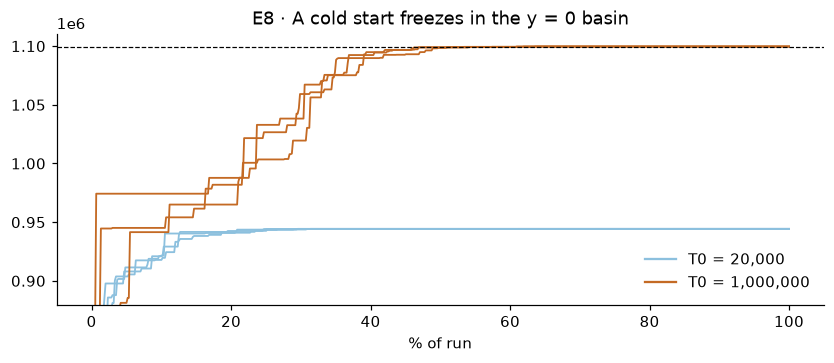

In [13]:
cold = [simulated_annealing(inst30, T0=20_000.0, seed=s) for s in SEEDS]
abl = pd.DataFrame({"T0 = 20,000": bench.summarize_runs(cold, Z), "T0 = 1,000,000": bench.summarize_runs(sa_runs, Z)}).loc[
    ["mean", "gap_mean_pct", "law_firm_active_count", "optimal_hit_count"]]
display(abl)
print("report:", {k: round(REPORT["ablation_sa_T0"]["T0_20k_stats"][k], 3) for k in ("mean", "gap_mean_pct", "law_firm_active_count")})
fig, ax = plt.subplots(figsize=(9, 3.2))
for r in cold: ax.plot(np.linspace(0, 100, len(r["history"])), r["history"], color=COLORS[1], lw=1.2)
for r in sa_runs: ax.plot(np.linspace(0, 100, len(r["history"])), r["history"], color=COLORS[4], lw=1.2)
ax.axhline(Z, color="k", ls="--", lw=0.8); ax.set_ylim(Z * 0.8, Z * 1.01); ax.set_xlabel("% of run")
ax.legend([plt.Line2D([], [], color=COLORS[1]), plt.Line2D([], [], color=COLORS[4])], ["T0 = 20,000", "T0 = 1,000,000"], frameon=False)
ax.set_title("E8 · A cold start freezes in the y = 0 basin"); plt.show()

**Why:** opening the law firm means paying $F$ = ฿40,000 and briefly violating $L=3$ (penalty $10^5\times 10$ per missing case). At $T_0=20{,}000$ SA almost never accepts that uphill step, so every seed stays without legal action (≈ 14% gap). At $T_0=10^6$ it crosses the barrier early and converges to $Z^*$.

---
## Part C — Scaling and capacity regimes

### E9. Six cohorts × all methods (`run_instance` from `src/03b_phase1_benchmark.py`)
| Cohort | Accounts | Limits ($B_{\max}, H, V, M$) | Law-firm contract |
|:--|:--|:--|:--|
| `N30_main` | TH0001–0030 | N=30 values | $F$ = ฿40k, $L$ = 3 |
| `N30_unseenB` | TH0031–0060 (unseen) | N=30 values | same |
| `N100_prop`, `N300_prop` | first 100 / 300 | scaled × N/30 (Regime 1) | same (a contract does not scale) |
| `N100_frozen`, `N300_frozen` | first 100 / 300 | kept at N=30 values (Regime 2, scarcity stress test) | same |

This cell runs the exact report code for every cohort (≈ 1–2 minutes) and compares with the saved report numbers.

In [14]:
COHORTS = {
    "N30_main":    (pool.iloc[:30],    bench.make_cfg(30, scale_caps=False),  10_000),
    "N30_unseenB": (pool.iloc[30:60],  bench.make_cfg(30, scale_caps=False),  10_000),
    "N100_prop":   (pool.iloc[:100],   bench.make_cfg(100, scale_caps=True),  1_000),
    "N300_prop":   (pool.iloc[:300],   bench.make_cfg(300, scale_caps=True),  0),
    "N100_frozen": (pool.iloc[:100],   bench.make_cfg(30, scale_caps=False),  0),
    "N300_frozen": (pool.iloc[:300],   bench.make_cfg(30, scale_caps=False),  0),
}
t0 = time.perf_counter()
live = {name: bench.run_instance(name, d, c, bb_nodes=n) for name, (d, c, n) in COHORTS.items()}
print(f"\nall cohorts done in {time.perf_counter() - t0:.0f}s")

[N30_main] N=30 | Z*=1,099,661.34 (0.047s) | LP_gap=1.411% (17 frac) | DP_UB=1,148,052.27 (0.002s) | Greedy_gap=15.63% (0.05s) | GA_mean_gap=0.20% (1.90s) | SA_mean_gap=0.00% (2.06s) | wall=17.5s


[N30_unseenB] N=30 | Z*=1,365,227.21 (0.077s) | LP_gap=1.929% (21 frac) | DP_UB=1,411,998.31 (0.002s) | Greedy_gap=14.38% (0.06s) | GA_mean_gap=0.57% (1.96s) | SA_mean_gap=0.00% (2.07s) | wall=14.3s


[N100_prop] N=100 | Z*=4,260,700.84 (0.389s) | LP_gap=0.086% (4 frac) | DP_UB=4,416,393.92 (0.020s) | Greedy_gap=20.65% (0.62s) | GA_mean_gap=0.78% (2.20s) | SA_mean_gap=0.26% (2.26s) | wall=21.7s


[N300_prop] N=300 | Z*=15,493,104.26 (0.325s) | LP_gap=0.013% (4 frac) | DP_UB=16,074,847.09 (0.155s) | Greedy_gap=20.99% (8.02s) | GA_mean_gap=2.29% (2.72s) | SA_mean_gap=0.68% (2.83s) | wall=26.1s


[N100_frozen] N=100 | Z*=2,803,548.13 (0.137s) | LP_gap=1.269% (23 frac) | DP_UB=3,705,862.11 (0.006s) | Greedy_gap=9.50% (0.37s) | GA_mean_gap=3.12% (2.16s) | SA_mean_gap=0.46% (2.25s) | wall=14.7s


[N300_frozen] N=300 | Z*=7,158,140.96 (0.387s) | LP_gap=1.280% (31 frac) | DP_UB=12,654,682.97 (0.019s) | Greedy_gap=4.19% (3.34s) | GA_mean_gap=3.94% (2.88s) | SA_mean_gap=2.91% (2.85s) | wall=24.0s

all cohorts done in 118s


In [15]:
def summary_row(r):
    z = r["exact_milp"]["objective"]
    return {"N": r["dimensions"]["accounts"], "vars": r["dimensions"]["total_vars"], "cons": r["dimensions"]["total_constraints"],
            "log10|S|": r["problem_size"]["log10"], "MILP Z*": z, "MILP s": r["exact_milp"]["time"],
            "root LP gap %": r["lp_relaxation"]["integrality_gap_pct"], "greedy gap %": r["greedy"]["gap_pct"],
            "GA gap %": r["ga_stats"]["gap_mean_pct"], "GA s": r["ga_stats"]["mean_time_s"],
            "SA gap %": r["sa_stats"]["gap_mean_pct"], "SA s": r["sa_stats"]["mean_time_s"]}
summary = pd.DataFrame({k: summary_row(v) for k, v in live.items()}).T
summary["report Z*"] = [REPORT["results"][k]["exact_milp"]["objective"] for k in summary.index]
summary["Z* matches report"] = (summary["MILP Z*"] - summary["report Z*"]).abs() < 0.01
summary["report SA gap %"] = [REPORT["results"][k]["sa_stats"]["gap_mean_pct"] for k in summary.index]
summary["report GA gap %"] = [REPORT["results"][k]["ga_stats"]["gap_mean_pct"] for k in summary.index]
display(summary)

,N,vars,cons,log10|S|,MILP Z*,MILP s,root LP gap %,greedy gap %,GA gap %,GA s,SA gap %,SA s,report Z*,Z* matches report,report SA gap %,report GA gap %
N30_main,30,161,61,21.74,"1,099,661",0.04685,1.411,15.63,0.2018,1.897,0,2.055,"1,099,661",True,0,0.2018
N30_unseenB,30,157,61,21.43,"1,365,227",0.07684,1.929,14.38,0.5682,1.961,0,2.074,"1,365,227",True,0,0.5682
N100_prop,100,533,191,72.32,"4,260,701",0.3891,0.08643,20.65,0.7782,2.199,0.2646,2.264,"4,260,701",True,0.2646,0.7782
N300_prop,300,"1,625",576,219.3,"15,493,104",0.3251,0.01263,20.99,2.287,2.716,0.6835,2.827,"15,493,104",True,0.6835,2.287
N100_frozen,100,533,191,72.32,"2,803,548",0.137,1.269,9.502,3.123,2.155,0.4559,2.248,"2,803,548",True,0.4559,3.123
N300_frozen,300,"1,625",576,219.3,"7,158,141",0.3871,1.28,4.19,3.941,2.882,2.914,2.847,"7,158,141",True,2.914,3.941


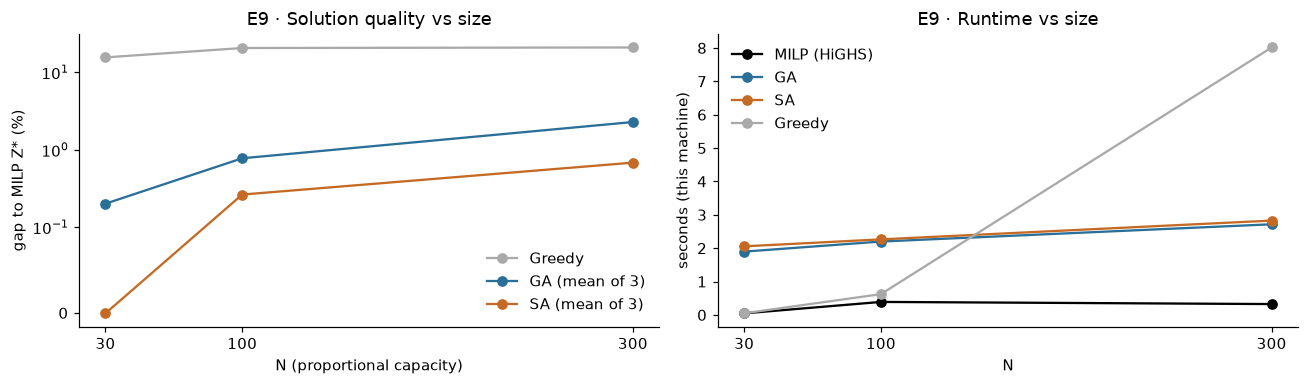

In [16]:
prop = ["N30_main", "N100_prop", "N300_prop"]
Ns = [30, 100, 300]
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
for col, c, lab in [("greedy gap %", COLORS[0], "Greedy"), ("GA gap %", COLORS[2], "GA (mean of 3)"), ("SA gap %", COLORS[4], "SA (mean of 3)")]:
    ax[0].plot(Ns, summary.loc[prop, col], "o-", color=c, label=lab)
ax[0].set_yscale("symlog", linthresh=0.1); ax[0].set_xticks(Ns); ax[0].set_xlabel("N (proportional capacity)"); ax[0].set_ylabel("gap to MILP Z* (%)"); ax[0].legend(frameon=False)
ax[0].set_title("E9 · Solution quality vs size")
for col, c, lab in [("MILP s", "k", "MILP (HiGHS)"), ("GA s", COLORS[2], "GA"), ("SA s", COLORS[4], "SA")]:
    ax[1].plot(Ns, summary.loc[prop, col], "o-", color=c, label=lab)
ax[1].plot(Ns, [live[k]["greedy"]["time"] for k in prop], "o-", color=COLORS[0], label="Greedy")
ax[1].set_xticks(Ns); ax[1].set_xlabel("N"); ax[1].set_ylabel("seconds (this machine)"); ax[1].legend(frameon=False); ax[1].set_title("E9 · Runtime vs size")
plt.tight_layout(); plt.show()

**Reading it (report §9–10):** HiGHS solves every cohort to a proven optimum in about 2 s; disaggregated linking ($x_{i,5}\le y$) shrinks the root LP gap from ≈ 1.4% at N=30 to ≈ 0.01% at N=300. Greedy stays 14–21% off. SA beats GA at every size; GA's uniform crossover breaks up tightly packed plans as N grows. Runtimes here differ from the report (different machine), but the objectives use the same seeds and code.

### E10. Strategy mix and shadow prices across cohorts

,none,sms,call,field,agency,legal,cost / budget,call h / H,legal cases,shadow budget,shadow call_hours,shadow field_slots,shadow hard_cap
N30_main,0,1,14,5,5,5,"147,575 / 150,000",10.5 / 12.0,5,1.277,0,"7,687","7,113"
N30_unseenB,0,1,14,5,6,4,"149,941 / 150,000",10.5 / 12.0,4,1.509,0,"7,915","6,818"
N100_prop,1,4,45,17,13,20,"499,890 / 500,000",33.75 / 40.0,20,1.515,0,"6,909","6,781"
N300_prop,7,14,129,50,40,60,"1,499,998 / 1,500,000",96.75 / 120.0,60,1.779,0,"9,041","8,207"
N100_frozen,7,62,16,5,6,4,"148,628 / 150,000",12.0 / 12.0,4,2.076,"16,937","32,859","28,894"
N300_frozen,37,232,16,5,7,3,"149,988 / 150,000",12.0 / 12.0,3,2.752,"42,910","71,653","65,174"


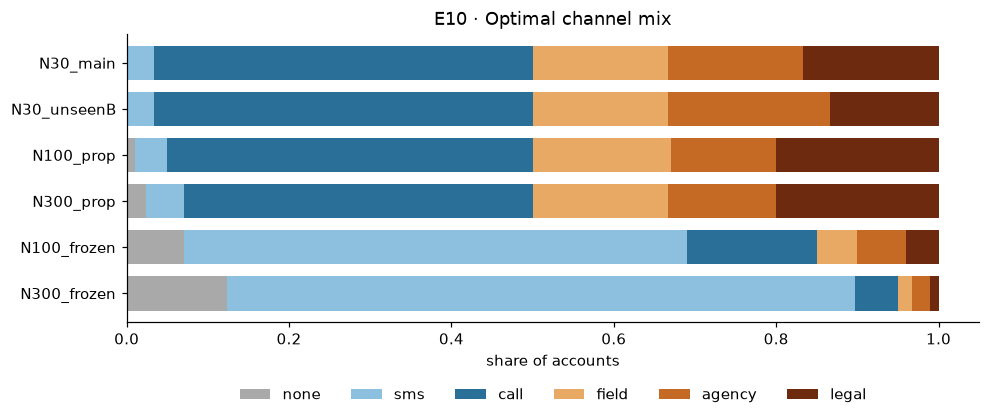

In [17]:
mix = pd.DataFrame({k: v["exact_milp"]["mix"] for k, v in live.items()}).T[KEYS]
share = mix.div(mix.sum(axis=1), axis=0)
shadow = pd.DataFrame({k: v["lp_relaxation"]["shadow_prices"] for k, v in live.items()}).T
use = pd.DataFrame({k: {"cost / budget": f"{v['exact_milp']['cost']:,.0f} / {v['cfg']['budget']:,.0f}",
                        "call h / H": f"{v['exact_milp']['call_hours']} / {v['cfg']['call_hours']}",
                        "legal cases": v["exact_milp"]["legal"]} for k, v in live.items()}).T
display(pd.concat([mix, use, shadow.add_prefix("shadow ")], axis=1))
ax = share.plot.barh(stacked=True, color=COLORS, figsize=(10, 3.4), width=0.75)
ax.invert_yaxis(); ax.set_xlabel("share of accounts"); ax.legend(ncol=6, frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.18))
ax.set_title("E10 · Optimal channel mix"); plt.show()

**Reading it:** with proportional capacity the mix is stable (≈ 45% call, 17% field, 13–20% agency, 13–20% legal). With **frozen** N=30 staffing, SMS/LINE jumps to 77% of accounts at N=300 and the shadow prices explode (≈ ฿43k per call hour, ≈ ฿72k per field visit): the model says where extra capacity would pay off most.

### E11. Is SA really better than GA? Wilcoxon signed-rank test
Pair the 18 GA and SA runs (6 cohorts × 3 seeds) and test the gap differences.

In [18]:
ga_gaps = [r["gap_pct"] for k in live for r in live[k]["ga_runs"]]
sa_gaps = [r["gap_pct"] for k in live for r in live[k]["sa_runs"]]
W, p = wilcoxon(sa_gaps, ga_gaps, zero_method="wilcox", alternative="two-sided")
print(f"pairs = {len(ga_gaps)}   mean gap GA = {np.mean(ga_gaps):.3f}%   SA = {np.mean(sa_gaps):.3f}%   W = {W}   p = {p:.5f}")
print("report:", {k: round(v, 5) for k, v in REPORT["pooled_stats"].items()})
pairs = pd.DataFrame({"cohort": [k for k in live for _ in SEEDS], "seed": SEEDS * len(live), "GA gap %": ga_gaps, "SA gap %": sa_gaps})
pairs["winner"] = np.select([pairs["SA gap %"] < pairs["GA gap %"], pairs["SA gap %"] > pairs["GA gap %"]], ["SA", "GA"], "tie")
print(pairs["winner"].value_counts().to_dict())
display(pairs[pairs["winner"] != "SA"])

pairs = 18   mean gap GA = 1.816%   SA = 0.720%   W = 1.0   p = 0.00035
report: {'n_paired_runs': 18, 'ga_mean_gap_pct': 1.81647, 'sa_mean_gap_pct': 0.71962, 'wilcoxon_stat': 1.0, 'wilcoxon_p_value': 0.00035}
{'SA': 16, 'tie': 1, 'GA': 1}


,cohort,seed,GA gap %,SA gap %,winner
1,N30_main,1,0,0,tie
17,N300_frozen,2,3.761,3.853,GA


**Result:** SA has the smaller gap in 16 of 18 pairs, ties in 1 (`N30_main` seed 1: both optimal) and loses 1 (`N300_frozen` seed 2: 3.85% vs 3.76%). The signed-rank test drops the tie and gives p = 0.00035, so SA is significantly better. The memo's wording "outperforms … across all 18 paired runs" should be read as "over the 18 pairs", not "in every pair".

---
## Part D — Multi-objective preview (Phase II)

### E12. ε-constraint Pareto front
Objectives: maximise gross recovery $f_1=\sum E[R_{i,k}]x_{i,k}$ and minimise cost $f_2=\sum c_{i,k}x_{i,k}+Fy$. The ε-constraint method solves $\max f_1$ s.t. $f_2\le\varepsilon$ (all other constraints kept) for 27 values of ε, each with the exact MILP (`pareto_front`, as in `src/03_run_experiments.py`).

27 MILPs in 1.2s


,eps,cost,gross,net
0,"10,000","10,000","1,067,134","869,147"
1,"25,000","19,250","1,140,836","919,846"
2,"40,000","19,250","1,140,836","919,846"
3,"55,000","19,250","1,140,836","919,846"
4,"70,000","19,250","1,140,836","919,846"
5,"85,000","19,250","1,140,836","919,846"
6,"100,000","99,929","1,214,409","968,358"
7,"115,000","114,630","1,253,405","1,016,772"
8,"130,000","129,879","1,281,677","1,050,250"
9,"145,000","144,838","1,306,668","1,077,553"


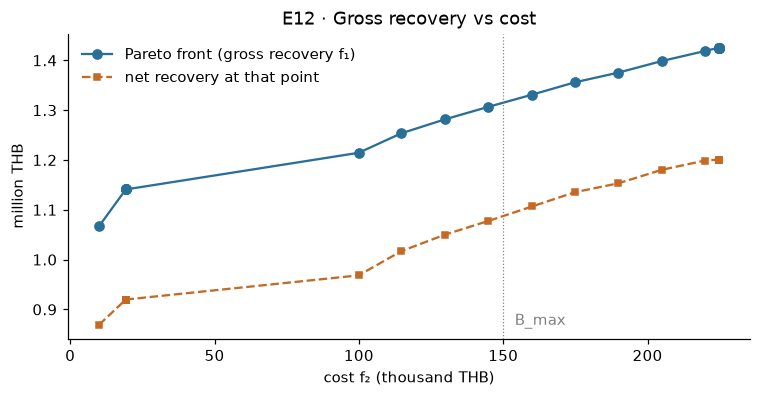

In [19]:
t0 = time.perf_counter()
pts = pd.DataFrame(pareto_front(df30, cfg30, np.linspace(10_000, 400_000, 27)))
print(f"{len(pts)} MILPs in {time.perf_counter() - t0:.1f}s")
display(pts[["eps", "cost", "gross", "net"]].round(0).head(10))
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.plot(pts["cost"] / 1e3, pts["gross"] / 1e6, "o-", color=COLORS[2], label="Pareto front (gross recovery f₁)")
ax.plot(pts["cost"] / 1e3, pts["net"] / 1e6, "s--", color=COLORS[4], ms=4, label="net recovery at that point")
ax.axvline(cfg30["budget"] / 1e3, color="grey", ls=":", lw=0.8); ax.text(cfg30["budget"] / 1e3 + 4, pts["net"].min() / 1e6, "B_max", color="grey")
ax.set_xlabel("cost f₂ (thousand THB)"); ax.set_ylabel("million THB"); ax.legend(frameon=False); ax.set_title("E12 · Gross recovery vs cost"); plt.show()

The front flattens once the agency + legal cap $M$ binds: beyond that, more money cannot buy stronger channels. Phase II will add a meta-heuristic multi-objective method (e.g. NSGA-II) and compare its front with this exact one.

---
## Part E — Verification checks and conclusions

In [20]:
checks = {
    "every MILP plan has zero violation": all(v["exact_milp"]["violation"] == 0 for v in live.values()),
    "every GA/SA run is feasible (36 runs)": all(r["feasible"] for v in live.values() for r in v["ga_runs"] + v["sa_runs"]),
    "Z* matches the report for all 6 cohorts": bool(summary["Z* matches report"].all()),
    "LP bound ≥ Z* everywhere": all(v["lp_relaxation"]["bound"] >= v["exact_milp"]["objective"] - 1e-6 for v in live.values()),
    "DP bound ≥ LP bound everywhere": all(v["dp_relaxation"]["objective"] >= v["lp_relaxation"]["bound"] - 1e-6 for v in live.values()),
    "SA mean ≥ GA mean everywhere": all(v["sa_stats"]["mean"] >= v["ga_stats"]["mean"] for v in live.values()),
    "Greedy never engages the law firm": all(v["greedy"]["law_firm"] == 0 for v in live.values()),
    "search space ≥ 3×10⁶ (course rule)": all(v["problem_size"]["size"] >= 3e6 for v in live.values()),
}
display(pd.Series(checks, name="passed").to_frame())
assert all(checks.values()), "a verification check failed"

,passed
every MILP plan has zero violation,True
every GA/SA run is feasible (36 runs),True
Z* matches the report for all 6 cohorts,True
LP bound ≥ Z* everywhere,True
DP bound ≥ LP bound everywhere,True
SA mean ≥ GA mean everywhere,True
Greedy never engages the law firm,True
search space ≥ 3×10⁶ (course rule),True


### Conclusions (report §10)
1. **The exact MILP is the right tool for this linear model.** HiGHS proves optimality for every cohort in ≈ 2 s, helped by the tight disaggregated linking constraint.
2. **Greedy fails structurally (14–21% gap).** The fixed ฿40,000 retainer plus the 3-case minimum is invisible to one-account-at-a-time improvement.
3. **SA is the stronger meta-heuristic.** Mean gap 0.72% vs 1.82% for GA, p = 0.00035, 100% feasible. Local flip and swap moves keep tightly packed plans intact; GA's uniform crossover breaks them.
4. **SA needs a hot start.** $T_0$ must be large enough to cross the retainer barrier (the E8 ablation).
5. **Shadow prices say what to buy.** Extra call hours are worth nothing; field visits, the agency/legal cap and budget are the bottlenecks, and they become very valuable when staffing is frozen.
6. **Why meta-heuristics still matter.** They do not depend on linearity. Non-linear response curves, black-box uplift models, or a multi-objective search (Phase II) would break the exact MILP approach but not GA or SA.

**Reproducibility notes**
- Everything stochastic is seeded, so this notebook reproduces the report's objectives exactly (Z*, all 36 GA/SA runs, the ablation and the Wilcoxon test).
- Runtimes depend on the machine: the report's timings came from a slower Linux machine, about 8× slower than a current laptop.
- B&B node counts and some shadow prices (for example the N100_prop field-visit dual) can differ slightly across SciPy/HiGHS versions, because the LP can have several optimal vertices or duals. Bounds and optima do not change.
- The report text says exposures "≥ \$500" are kept; the code uses "> \$500".